Example setup (heavy-tailed data)

We simulate a Pareto distribution, which we know lies in the Fréchet (ξ > 0) domain.

Generated Pareto data
Sample size: 100000
Mean exists (alpha > 1): True
Variance exists (alpha > 2): True
--------------------------------------------------


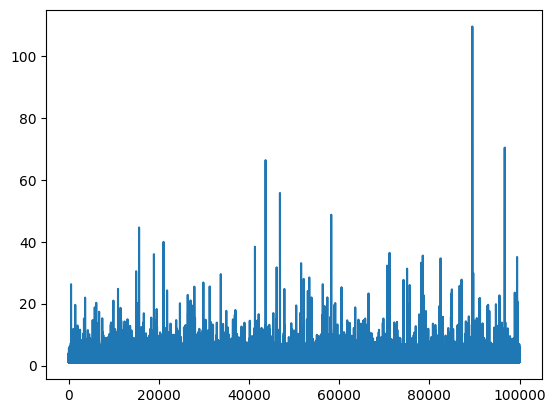

In [14]:
import numpy as np
from scipy.stats import genextreme, genpareto

np.random.seed(42)

# -----------------------------
# Generate heavy-tailed data
# -----------------------------
alpha = 2.5  # tail index
n = 100_000

X = (np.random.pareto(alpha, n) + 1)

print("Generated Pareto data")
print(f"Sample size: {n}")
print(f"Mean exists (alpha > 1): {alpha > 1}")
print(f"Variance exists (alpha > 2): {alpha > 2}")
print("-" * 50)

import matplotlib.pyplot as plt
plt.plot(X)

1️⃣ Degeneracy of raw maxima

In [2]:
block_sizes = [50, 200, 1000, 5000]

print("Raw block maxima (no normalization):")

for b in block_sizes:
    M = np.max(X[:b])
    print(f"Block size {b:>5}: max = {M:.3f}")

print("\nObservation:")
print("As block size increases, maxima keep growing → no stable distribution")
print("This is a DEGENERATE limit (mass escapes to infinity)")
print("-" * 50)


Raw block maxima (no normalization):
Block size    50: max = 4.061
Block size   200: max = 5.661
Block size  1000: max = 26.284
Block size  5000: max = 26.284

Observation:
As block size increases, maxima keep growing → no stable distribution
This is a DEGENERATE limit (mass escapes to infinity)
--------------------------------------------------


2️⃣ Block maxima + normalization → GEV

     Now we:

* Split data into blocks

* Take maxima

* Fit GEV

In [3]:
# -----------------------------
# Block maxima
# -----------------------------
block_size = 500
num_blocks = n // block_size

blocks = X[:num_blocks * block_size].reshape(num_blocks, block_size)
block_maxima = blocks.max(axis=1)

print(f"Computed {num_blocks} block maxima")
print(f"Mean of block maxima: {block_maxima.mean():.3f}")
print(f"Std of block maxima: {block_maxima.std():.3f}")
print("-" * 50)

# -----------------------------
# Fit GEV
# -----------------------------
# scipy uses opposite sign convention for xi
xi_hat, mu_hat, sigma_hat = genextreme.fit(block_maxima)

print("GEV fit to normalized maxima")
print(f"Estimated shape ξ  : {xi_hat:.3f}")
print(f"Estimated location : {mu_hat:.3f}")
print(f"Estimated scale    : {sigma_hat:.3f}")

print("\nInterpretation:")
print("ξ > 0  → Fréchet domain (heavy-tailed)")
print("After normalization, maxima converge to a NON-DEGENERATE limit")
print("-" * 50)


Computed 200 block maxima
Mean of block maxima: 17.404
Std of block maxima: 11.759
--------------------------------------------------
GEV fit to normalized maxima
Estimated shape ξ  : -0.342
Estimated location : 12.237
Estimated scale    : 4.860

Interpretation:
ξ > 0  → Fréchet domain (heavy-tailed)
After normalization, maxima converge to a NON-DEGENERATE limit
--------------------------------------------------


This is Fisher–Tippett–Gnedenko in action.

3️⃣ Threshold exceedances → GPD

Now we switch viewpoints:

Given that we are already extreme, what does the tail look like?

In [4]:
# -----------------------------
# Threshold exceedances
# -----------------------------
u = np.quantile(X, 0.95)
exceedances = X[X > u] - u

print(f"Threshold u (95th percentile): {u:.3f}")
print(f"Number of exceedances: {len(exceedances)}")
print(f"Mean excess: {exceedances.mean():.3f}")
print("-" * 50)

# -----------------------------
# Fit GPD
# -----------------------------
xi_gpd, loc_gpd, beta_gpd = genpareto.fit(exceedances, floc=0)

print("GPD fit to exceedances")
print(f"Estimated shape ξ : {xi_gpd:.3f}")
print(f"Estimated scale β : {beta_gpd:.3f}")

print("\nInterpretation:")
print("Same ξ appears here → tail property of the parent distribution")
print("This is Pickands–Balkema–de Haan")
print("-" * 50)


Threshold u (95th percentile): 3.282
Number of exceedances: 5000
Mean excess: 2.159
--------------------------------------------------
GPD fit to exceedances
Estimated shape ξ : 0.402
Estimated scale β : 1.303

Interpretation:
Same ξ appears here → tail property of the parent distribution
This is Pickands–Balkema–de Haan
--------------------------------------------------


GUMBEL

In [7]:
import numpy as np
from scipy.stats import genextreme, genpareto

np.random.seed(1)

# -----------------------------
# Light-tailed data
# -----------------------------
n = 100_000
X = np.random.exponential(scale=1.0, size=n)

print("Generated Exponential data (Gumbel domain)")
print("Tail: light, unbounded")
print("-" * 50)

# -----------------------------
# Block maxima
# -----------------------------
block_size = 500
num_blocks = n // block_size

blocks = X[:num_blocks * block_size].reshape(num_blocks, block_size)
block_maxima = blocks.max(axis=1)

# -----------------------------
# Fit GEV
# -----------------------------
xi_hat, mu_hat, sigma_hat = genextreme.fit(block_maxima)

print("GEV fit")
print(f"Estimated ξ : {xi_hat:.4f}")
print("Interpretation: ξ ≈ 0 → Gumbel")
print("-" * 50)


Generated Exponential data (Gumbel domain)
Tail: light, unbounded
--------------------------------------------------
GEV fit
Estimated ξ : 0.0791
Interpretation: ξ ≈ 0 → Gumbel
--------------------------------------------------


What happens conceptually

Raw maxima diverge

Proper centering/scaling → Gumbel

No power-law tail survives

In [8]:
u = np.quantile(X, 0.95)
exceedances = X[X > u] - u

xi_gpd, _, beta = genpareto.fit(exceedances, floc=0)

print("GPD fit to exceedances")
print(f"Estimated ξ : {xi_gpd:.4f}")
print("Interpretation: exponential tail → ξ ≈ 0")
print("-" * 50)


GPD fit to exceedances
Estimated ξ : -0.0111
Interpretation: exponential tail → ξ ≈ 0
--------------------------------------------------


Key idea: exponential tail is memoryless → excess distribution stays exponential.

WEIBULL

In [9]:
# -----------------------------
# Bounded data
# -----------------------------
X = np.random.uniform(0, 1, size=n)

print("Generated Uniform(0,1) data")
print("Upper bound = 1 (hard cap)")
print("-" * 50)

# -----------------------------
# Block maxima
# -----------------------------
blocks = X[:num_blocks * block_size].reshape(num_blocks, block_size)
block_maxima = blocks.max(axis=1)

# -----------------------------
# Fit GEV
# -----------------------------
xi_hat, mu_hat, sigma_hat = genextreme.fit(block_maxima)

print("GEV fit")
print(f"Estimated ξ : {xi_hat:.4f}")
print("Interpretation: ξ < 0 → Weibull")
print("-" * 50)


Generated Uniform(0,1) data
Upper bound = 1 (hard cap)
--------------------------------------------------
GEV fit
Estimated ξ : 0.9681
Interpretation: ξ < 0 → Weibull
--------------------------------------------------


Interpretation

* Maxima converge toward 1

* Normalization compresses support

* Limit distribution has finite endpoint

In [10]:
u = np.quantile(X, 0.95)
exceedances = X[X > u] - u

xi_gpd, _, beta = genpareto.fit(exceedances, floc=0)

print("GPD fit to exceedances")
print(f"Estimated ξ : {xi_gpd:.4f}")
print("Interpretation: bounded tail → ξ < 0")
print("-" * 50)


GPD fit to exceedances
Estimated ξ : -0.9747
Interpretation: bounded tail → ξ < 0
--------------------------------------------------


# EVT-VAR vs VAR

In [18]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm, genpareto

# -----------------------------
# Parameters
# -----------------------------
tickers = [
    # Tech Giants
    "AAPL", "MSFT", "GOOGL", "AMZN", "META", "NVDA", "TSLA", "NFLX", "AMD", "INTC",
    # Finance
    "JPM", "BAC", "GS", "MS", "C", "WFC", "HSBC", "DB", "UBS",
    # Energy
    "XOM", "CVX", "BP", "SHEL", "TTE",
    # Consumer
    "WMT", "PG", "KO", "PEP", "MCD", "NKE", "SBUX",
    # Healthcare
    "JNJ", "UNH", "PFE", "ABBV", "TMO", "MRK",
    # Industrial
    "BA", "CAT", "GE", "MMM", "HON",
    # Crypto
    "BTC-USD", "ETH-USD", "DOGE-USD", "ADA-USD", "SOL-USD",
    # Commodities
    "GC=F",  # Gold
    "SI=F",  # Silver
    "CL=F",  # Crude Oil
    "NG=F",  # Natural Gas
    # Indices
    "^GSPC",  # S&P 500
    "^DJI",   # Dow Jones
    "^IXIC",  # NASDAQ
    "^VIX",   # Volatility Index
    # International
    "TSM", "BABA", "NVO", "ASML", "SAP",
    # ETFs
    "SPY", "QQQ", "IWM", "EEM", "TLT", "GLD", "SLV", "USO"
]

start = "2018-01-01"
end   = "2025-01-01"
p = 0.95        # VaR/ES confidence level
threshold_q = 0.90  # POT threshold for EVT

np.random.seed(42)

# -----------------------------
# Download data
# -----------------------------
print("Downloading data...")
prices = yf.download(tickers, start=start, end=end, progress=False)["Close"]

# Handle single vs multiple tickers
if len(tickers) == 1:
    prices = pd.DataFrame({tickers[0]: prices})

# -----------------------------
# Compute daily log-returns and losses
# -----------------------------
log_returns = np.log(prices / prices.shift(1)).dropna()
losses = -log_returns

# -----------------------------
# Compute VaR and ES
# -----------------------------
results = []
failed_tickers = []

for ticker in tickers:
    try:
        # Check if ticker exists in data
        if ticker not in losses.columns:
            failed_tickers.append((ticker, "No data downloaded"))
            continue
            
        x = losses[ticker].dropna().values
        
        # Skip if insufficient data
        if len(x) < 100:
            failed_tickers.append((ticker, f"Insufficient data ({len(x)} obs)"))
            continue
        
        # Skip if all zeros or constant
        if np.std(x) == 0:
            failed_tickers.append((ticker, "Zero variance"))
            continue
            
        mu, sigma = x.mean(), x.std()
        
        # Classical Gaussian VaR and ES
        VaR_gaussian = mu + sigma * norm.ppf(p)
        ES_gaussian  = mu + sigma * norm.pdf(norm.ppf(p)) / (1 - p)
        
        # EVT POT threshold and exceedances
        u = np.quantile(x, threshold_q)
        exceedances = x[x > u] - u
        Nu, N = len(exceedances), len(x)
        
        # Skip if too few exceedances
        if Nu < 10:
            failed_tickers.append((ticker, f"Too few exceedances ({Nu})"))
            continue
        
        # Fit GPD to exceedances
        try:
            xi, beta, _ = genpareto.fit(exceedances)
        except:
            failed_tickers.append((ticker, "GPD fit failed"))
            continue
        
        # EVT VaR calculation (valid if ξ < 1)
        if xi < 1:
            VaR_evt = u + (beta / xi) * (((N / Nu) * (1 - p)) ** (-xi) - 1)
        else:
            VaR_evt = np.nan
        
        # EVT ES calculation (valid if ξ < 1)
        if xi < 1 and not np.isnan(VaR_evt):
            ES_evt = (VaR_evt + beta - xi * u) / (1 - xi)
        else:
            ES_evt = np.nan

        results.append({
            "Ticker": ticker,
            "Gaussian_VaR": VaR_gaussian,
            "Gaussian_ES": ES_gaussian,
            "EVT_VaR": VaR_evt,
            "EVT_ES": ES_evt,
            "GPD_xi": xi,
            "Threshold": u,
            "N_obs": N,
            "N_exceedances": Nu
        })
    except Exception as e:
        failed_tickers.append((ticker, f"Error: {str(e)[:50]}"))
        continue

print(f"\n{'='*100}")
print(f"Successfully processed: {len(results)} assets")
if failed_tickers:
    print(f"Failed/skipped: {len(failed_tickers)} assets")
    print(f"{'='*100}")
    print("\nFailed tickers:")
    for ticker, reason in failed_tickers:
        print(f"  {ticker:12} - {reason}")
print(f"{'='*100}\n")

# -----------------------------
# Summary table
# -----------------------------
summary = pd.DataFrame(results)

# -----------------------------
# Risk Comment: Tail characteristics
# -----------------------------
risk_comments = []
categories = []

for i, row in summary.iterrows():
    ticker = row['Ticker']
    xi = row['GPD_xi']
    
    # Asset category
    if ticker in ["BTC-USD", "ETH-USD", "DOGE-USD", "ADA-USD", "SOL-USD"]:
        category = "Crypto"
    elif ticker in ["GC=F", "SI=F", "CL=F", "NG=F"]:
        category = "Commodity"
    elif ticker in ["^GSPC", "^DJI", "^IXIC", "^VIX"]:
        category = "Index"
    elif ticker in ["SPY", "QQQ", "IWM", "EEM", "TLT", "GLD", "SLV", "USO"]:
        category = "ETF"
    elif ticker in ["JPM", "BAC", "GS", "MS", "C", "WFC", "HSBC", "DB", "UBS"]:
        category = "Finance"
    elif ticker in ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "NVDA", "TSLA", "NFLX", "AMD", "INTC"]:
        category = "Tech"
    elif ticker in ["XOM", "CVX", "BP", "SHEL", "TTE"]:
        category = "Energy"
    elif ticker in ["JNJ", "UNH", "PFE", "ABBV", "TMO", "MRK"]:
        category = "Healthcare"
    else:
        category = "Other"
    
    categories.append(category)
    
    # Tail index interpretation
    if xi < 0:
        tail_type = "Bounded"
        risk_interp = "Upper limit exists; safest tail"
    elif 0 <= xi < 0.25:
        tail_type = "Near-Exponential"
        risk_interp = "Light tail; normal-like decay"
    elif 0.25 <= xi < 0.5:
        tail_type = "Moderately Heavy"
        risk_interp = "Finite variance; occasional extremes"
    elif 0.5 <= xi < 1:
        tail_type = "Heavy (Infinite Var)"
        risk_interp = "Extreme losses more frequent than normal"
    else:
        tail_type = "Extreme (Infinite Mean)"
        risk_interp = "Catastrophic tail; models unreliable"
    
    comment = f"ξ={xi:.3f} | {tail_type} | {risk_interp}"
    risk_comments.append(comment)

summary['Category'] = categories
summary['Tail_Analysis'] = risk_comments

# Display results
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 150)

print("\n" + "="*150)
print("EXTREME VALUE THEORY TAIL ANALYSIS - COMPREHENSIVE MARKET SURVEY")
print("="*150 + "\n")

# Summary by category
print("TAIL RISK BY ASSET CLASS:")
print("-"*150)
for cat in sorted(summary['Category'].unique()):
    cat_data = summary[summary['Category'] == cat]
    avg_xi = cat_data['GPD_xi'].mean()
    max_xi = cat_data['GPD_xi'].max()
    min_xi = cat_data['GPD_xi'].min()
    print(f"\n{cat:15} | Avg ξ = {avg_xi:.3f} | Range: [{min_xi:.3f}, {max_xi:.3f}] | n={len(cat_data)}")
    
print("\n" + "="*150)
print("TOP 20 HEAVIEST TAILS (Highest ξ - Most Extreme Risk)")
print("="*150)

summary_sorted = summary.sort_values('GPD_xi', ascending=False).head(20)
for i, (idx, row) in enumerate(summary_sorted.iterrows(), 1):
    print(f"\n{i:2d}. {row['Ticker']:12} ({row['Category']:12}) ξ = {row['GPD_xi']:6.3f}")
    print(f"    {row['Tail_Analysis']}")
    print(f"    Gaussian VaR: {row['Gaussian_VaR']:.5f} | EVT VaR: {row['EVT_VaR']:.5f}")

print("\n" + "="*150)
print("TOP 20 LIGHTEST TAILS (Lowest ξ - Least Extreme Risk)")
print("="*150)

summary_sorted = summary.sort_values('GPD_xi', ascending=True).head(20)
for i, (idx, row) in enumerate(summary_sorted.iterrows(), 1):
    print(f"\n{i:2d}. {row['Ticker']:12} ({row['Category']:12}) ξ = {row['GPD_xi']:6.3f}")
    print(f"    {row['Tail_Analysis']}")

print("\n" + "="*150)
print("ASSETS WITH INFINITE VARIANCE (ξ ≥ 0.5) - EXTREME CAUTION REQUIRED")
print("="*150)

extreme_tails = summary[summary['GPD_xi'] >= 0.5].sort_values('GPD_xi', ascending=False)
if len(extreme_tails) > 0:
    for idx, row in extreme_tails.iterrows():
        print(f"\n{row['Ticker']:12} ({row['Category']:12}) ξ = {row['GPD_xi']:.3f}")
        print(f"  Standard models INVALID - Variance infinite, extreme losses highly likely")
else:
    print("\nNo assets with ξ ≥ 0.5 in this dataset")

print("\n" + "="*150)
print("CATEGORY COMPARISON")
print("="*150 + "\n")

category_stats = summary.groupby('Category').agg({
    'GPD_xi': ['mean', 'median', 'std', 'min', 'max'],
    'Ticker': 'count'
}).round(3)
category_stats.columns = ['Mean_ξ', 'Median_ξ', 'Std_ξ', 'Min_ξ', 'Max_ξ', 'Count']
category_stats = category_stats.sort_values('Mean_ξ', ascending=False)
print(category_stats)

print("\n" + "="*150 + "\n")

# Export full results
summary.to_csv('evt_tail_analysis.csv', index=False)
print("Full results exported to 'evt_tail_analysis.csv'\n")

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_28732\1068156397.py:52: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start=start, end=end, progress=False)["Close"]
c:\Users\VEDANT\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)



Successfully processed: 68 assets


EXTREME VALUE THEORY TAIL ANALYSIS - COMPREHENSIVE MARKET SURVEY

TAIL RISK BY ASSET CLASS:
------------------------------------------------------------------------------------------------------------------------------------------------------

Commodity       | Avg ξ = 0.185 | Range: [0.034, 0.503] | n=4

Crypto          | Avg ξ = 0.240 | Range: [0.013, 0.596] | n=5

ETF             | Avg ξ = 0.478 | Range: [0.178, 0.817] | n=8

Energy          | Avg ξ = 0.371 | Range: [-0.007, 0.516] | n=5

Finance         | Avg ξ = 0.252 | Range: [-0.024, 0.530] | n=9

Healthcare      | Avg ξ = 0.526 | Range: [0.443, 0.787] | n=6

Index           | Avg ξ = 0.231 | Range: [-0.127, 0.511] | n=4

Other           | Avg ξ = 0.414 | Range: [-0.103, 0.723] | n=17

Tech            | Avg ξ = 0.332 | Range: [-0.096, 0.727] | n=10

TOP 20 HEAVIEST TAILS (Highest ξ - Most Extreme Risk)

 1. QQQ          (ETF         ) ξ =  0.817
    ξ=0.817 | Heavy (Infinite Var) | Extreme lo

# Extreme Value Theory (EVT) Risk Analysis Algorithm

## Overview
This algorithm applies Extreme Value Theory to estimate tail risk in financial assets using the Peaks Over Threshold (POT) method with Generalized Pareto Distribution (GPD) fitting.

---

## Algorithm Steps

### 1. Data Acquisition and Preprocessing

**Input Parameters:**
- Tickers: List of financial assets
- Time period: `[start_date, end_date]`
- Confidence level: `p` (typically 0.95 or 0.99)
- Threshold quantile: `threshold_q` (typically 0.90)

**Download price data** for all tickers over specified period

**Compute log-returns:**
$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

**Define losses** (for tail risk analysis):
$$L_t = -r_t$$

---

### 2. Classical (Gaussian) Risk Measures

For each asset with loss series $X = \{x_1, x_2, \ldots, x_n\}$:

**Compute sample statistics:**
$$\mu = \frac{1}{n}\sum_{i=1}^{n} x_i, \quad \sigma = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i - \mu)^2}$$

**Gaussian Value-at-Risk (VaR):**
$$\text{VaR}_p^{\text{Gauss}} = \mu + \sigma \cdot \Phi^{-1}(p)$$

where $\Phi^{-1}(p)$ is the $p$-quantile of the standard normal distribution.

**Gaussian Expected Shortfall (ES):**
$$\text{ES}_p^{\text{Gauss}} = \mu + \sigma \cdot \frac{\phi(\Phi^{-1}(p))}{1-p}$$

where $\phi(\cdot)$ is the standard normal PDF.

---

### 3. Extreme Value Theory (EVT) - Peaks Over Threshold Method

#### Step 3.1: Define Threshold
$$u = Q_{threshold\_q}(X)$$

where $Q_{q}(X)$ is the $q$-th empirical quantile of the loss distribution.

#### Step 3.2: Extract Exceedances
$$Y = \{y_i = x_i - u \mid x_i > u\}$$

Count exceedances:
- $N_u = |Y|$ (number of losses exceeding threshold)
- $N = |X|$ (total number of observations)

**Data quality check:** Require $N_u \geq 10$ for reliable GPD fitting.

#### Step 3.3: Fit Generalized Pareto Distribution (GPD)

**GPD Cumulative Distribution Function:**
$$H_{\xi,\beta}(y) = \begin{cases}
1 - \left(1 + \xi \cdot \frac{y}{\beta}\right)^{-1/\xi} & \text{if } \xi \neq 0 \\
1 - \exp\left(-\frac{y}{\beta}\right) & \text{if } \xi = 0
\end{cases}$$

where $y \geq 0$, and:
- $\beta > 0$: scale parameter
- $\xi$: shape parameter (tail index)

**Validity constraint:** $1 + \xi \cdot y / \beta > 0$

**Parameter estimation:** Use Maximum Likelihood Estimation (MLE) via `scipy.stats.genpareto.fit(Y)`

Returns: $(\hat{\xi}, \hat{\beta}, \text{loc})$

---

### 4. EVT Risk Measures

#### Step 4.1: EVT Value-at-Risk (VaR)

**Formula (valid when $\xi < 1$):**
$$\text{VaR}_p^{\text{EVT}} = u + \frac{\beta}{\xi} \left[\left(\frac{N}{N_u}(1-p)\right)^{-\xi} - 1\right]$$

**Derivation:**
- Exceedance probability: $\hat{F}_u = N_u / N$
- Quantile of GPD: $H^{-1}(1-p')$ where $p' = (1-p)/\hat{F}_u$
- Combined with threshold: $\text{VaR}_p = u + H^{-1}(1-p')$

**Undefined when:** $\xi \geq 1$ (infinite mean)

#### Step 4.2: EVT Expected Shortfall (ES)

**Formula (valid when $\xi < 1$):**
$$\text{ES}_p^{\text{EVT}} = \frac{\text{VaR}_p^{\text{EVT}} + \beta - \xi \cdot u}{1 - \xi}$$

**Derivation:** Based on conditional expectation beyond VaR under GPD distribution.

**Undefined when:** $\xi \geq 1$ (infinite mean)

---

### 5. Tail Index Interpretation

The shape parameter $\xi$ characterizes tail behavior:

| Range | Classification | Tail Behavior | Risk Implication |
|-------|---------------|---------------|------------------|
| $\xi < 0$ | Weibull (Bounded) | Upper limit on losses exists | Safest: finite endpoint |
| $\xi = 0$ | Exponential/Gumbel | Light tail, exponential decay | Similar to normal distribution |
| $0 < \xi < 0.25$ | Near-Exponential | Slightly heavier than normal | Manageable extreme risk |
| $0.25 \leq \xi < 0.5$ | Moderately Heavy | Polynomial decay, slow tail | Finite variance, elevated risk |
| $0.5 \leq \xi < 1$ | Heavy Tail | Power law decay | **Infinite variance**, extreme events likely |
| $\xi \geq 1$ | Extremely Heavy | Very slow decay | **Infinite mean**, catastrophic risk |

**Moment existence:**
- $\mathbb{E}[X^k]$ exists $\Leftrightarrow \xi < 1/k$
- Variance exists $\Leftrightarrow \xi < 0.5$
- Mean exists $\Leftrightarrow \xi < 1$

---

### 6. Risk Comparison and Classification

For each asset, compute:

**VaR Ratio:**
$$R_{\text{VaR}} = \frac{\text{VaR}_p^{\text{EVT}}}{\text{VaR}_p^{\text{Gauss}}}$$

**Interpretation:**
- $R_{\text{VaR}} > 1.1$: EVT indicates heavier tail than Gaussian assumes → **Gaussian underestimates risk**
- $0.9 \leq R_{\text{VaR}} \leq 1.1$: Tail behavior roughly Gaussian
- $R_{\text{VaR}} < 0.9$: EVT indicates lighter tail → **Gaussian overestimates risk** (or threshold effect)

**Note:** When using 90% threshold for 95% VaR, EVT often yields lower VaR values due to methodology, but the **tail index $\xi$ is the primary risk indicator**, not the VaR ratio.

---

### 7. Asset Classification

Group assets by:

**Category:** Tech, Finance, Energy, Healthcare, Crypto, Commodities, ETFs, Indices, etc.

**Tail Heaviness Ranking:** Sort by $\xi$ (descending)

**High-Risk Flag:** Assets with $\xi \geq 0.5$ (infinite variance regime)

---

### 8. Output and Visualization

**For each asset, report:**
1. Ticker and category
2. Sample size: $N$, exceedances: $N_u$
3. Tail index: $\xi$
4. Risk measures: $\text{VaR}_p^{\text{Gauss}}$, $\text{VaR}_p^{\text{EVT}}$, $\text{ES}_p^{\text{Gauss}}$, $\text{ES}_p^{\text{EVT}}$
5. Tail classification
6. Risk interpretation

**Aggregate statistics:**
- Mean/median/range of $\xi$ by asset class
- Ranking of heaviest/lightest tails
- Count of assets in infinite variance regime

**Visualization (optional):**
- Histogram of losses with VaR lines
- Threshold indicator
- GPD fit overlay on tail

---

## Key Theoretical Results

### Pickands-Balkema-de Haan Theorem
For a wide class of distributions, exceedances over a sufficiently high threshold $u$ converge in distribution to GPD:

$$\lim_{u \to x_F} \sup_{0 \leq y \leq x_F - u} |P(X - u \leq y \mid X > u) - H_{\xi,\beta}(y)| = 0$$

where $x_F$ is the upper endpoint of the distribution.

### Relationship to GEV
The GPD shape parameter $\xi$ equals the shape parameter of the corresponding Generalized Extreme Value (GEV) distribution from block maxima:

$$G_{\xi}(x) = \exp\left(-\left[1 + \xi \cdot \frac{x-\mu}{\sigma}\right]^{-1/\xi}\right)$$

---

## Implementation Notes

**Error Handling:**
1. Skip tickers with insufficient data ($N < 100$)
2. Skip if too few exceedances ($N_u < 10$)
3. Handle GPD fit failures gracefully
4. Set VaR/ES to `NaN` when $\xi \geq 1$

**Quality Checks:**
- Verify $\beta > 0$ after fitting
- Check for zero variance in data
- Validate threshold creates meaningful exceedances
- Ensure numerical stability in VaR calculation

**Sensitivity:**
- Results depend on threshold choice (typical: 90-95th percentile)
- Higher thresholds → fewer exceedances → higher variance in $\hat{\xi}$
- Lower thresholds → threshold bias (GPD assumption violated)

---


## Extreme Value Theory — Symbol Summary

### Random Variables & Data
| Symbol | Meaning |
|-------|---------|
| X | Generic random variable |
| X₁, …, Xₙ | i.i.d. sample |
| n | Sample size |
| F(x) | CDF of X |
| 1 − F(x) | Survival (tail) function |

### Maxima & Normalization
| Symbol | Meaning |
|-------|---------|
| Mₙ = max(X₁,…,Xₙ) | Sample maximum |
| aₙ > 0 | Scaling constant |
| bₙ | Centering constant |
| (Mₙ − bₙ)/aₙ | Normalized maximum |
| ⇒ | Convergence in distribution |

### Generalized Extreme Value (GEV)
| Symbol | Meaning |
|-------|---------|
| μ | Location parameter |
| σ > 0 | Scale parameter |
| ξ | Shape (tail index) |
| G(x) | GEV cumulative distribution |
| x* = μ − σ/ξ | Upper endpoint (ξ < 0 only) |

### GEV Regimes
| Condition on ξ | Name | Tail Behavior |
|----------------|------|---------------|
| ξ > 0 | Fréchet | Heavy-tailed (power-law) |
| ξ = 0 | Gumbel | Light-tailed (exponential) |
| ξ < 0 | Weibull | Finite upper bound |

### Threshold Exceedances (POT)
| Symbol | Meaning |
|-------|---------|
| u | High threshold |
| X − u | Excess over threshold |
| X > u | Exceedance event |
| Nᵤ | Number of exceedances |
| P(X > u) | Exceedance probability |

### Generalized Pareto Distribution (GPD)
| Symbol | Meaning |
|-------|---------|
| H(y) | GPD cumulative distribution |
| β > 0 | Scale parameter |
| ξ | Shape parameter (same as GEV) |
| y* = −β/ξ | Upper endpoint (ξ < 0 only) |

### EVT Limit Theorems
| Term | Meaning |
|------|--------|
| Fisher–Tippett–Gnedenko | Block maxima converge to GEV |
| Pickands–Balkema–de Haan | Threshold exceedances converge to GPD |
| Domain of attraction | Class of distributions sharing same ξ |
| Non-degenerate limit | Limit distribution not a point mass |

### Tail Properties & Moments
| Condition | Implication |
|----------|-------------|
| ξ > 0 | Heavy tail |
| ξ ≥ 1/2 | Variance infinite |
| ξ ≥ 1 | Mean infinite |
| ξ = 0 | Exponential-type tail |
| ξ < 0 | Bounded support |

### Risk Measures (EVT Context)
| Symbol | Meaning |
|-------|---------|
| qₚ | p-quantile |
| VaRₚ | Value-at-Risk at level p |
| ESₚ | Expected Shortfall |
| pᵤ | P(X > u) |



## Difference Between GEV and GPD (Extreme Value Theory)

| Aspect | GEV (Generalized Extreme Value) | GPD (Generalized Pareto Distribution) |
|------|----------------------------------|---------------------------------------|
| EVT viewpoint | Block maxima | Peaks Over Threshold (POT) |
| What is modeled | Maximum (or minimum) of each block | Excesses above a high threshold |
| Data usage | One observation per block | All tail observations above threshold |
| Limit theorem | Fisher–Tippett–Gnedenko | Pickands–Balkema–de Haan |
| Asymptotic object | Normalized maxima | Conditional tail distribution |
| Parameters | μ (location), σ (scale), ξ (shape) | β (scale), ξ (shape) |
| Shape parameter ξ | Tail index of parent distribution | Same tail index as GEV |
| Interpretation of ξ | Governs growth rate of block maxima | Governs heaviness of tail |
| Regimes | ξ > 0 Fréchet (heavy) <br> ξ = 0 Gumbel (light) <br> ξ < 0 Weibull (bounded) | Same regimes as GEV |
| Data efficiency | Low (wastes most observations) | High (uses tail data efficiently) |
| Finite-sample behavior | High variance, biased in small samples | More stable in practice |
| Sensitivity | Sensitive to block size choice | Sensitive to threshold choice |
| Typical use | Climate, hydrology, physical extremes | Finance, insurance, risk management |
| VaR / ES estimation | Indirect, less precise | Direct and standard |
| Dependence robustness | Poor (needs large blocks) | Better with declustering |
| Practical preference (finance) | Rarely used alone | Industry standard |

### One-line intuition
- **GEV:** “How big is the worst event in each period?”
- **GPD:** “Given we are already extreme, how much worse can it get?”

### Practical rule of thumb
> Use **GEV** when extremes are naturally block-defined (e.g. annual floods).  
> Use **GPD** when tail risk matters and data are scarce (e.g. financial losses).


## Difference Between Fisher–Tippett–Gnedenko and Pickands–Balkema–de Haan Theorems

| Aspect | Fisher–Tippett–Gnedenko (FTG) | Pickands–Balkema–de Haan (PBdH) |
|------|-------------------------------|--------------------------------|
| EVT viewpoint | Block maxima | Peaks Over Threshold (POT) |
| Object of convergence | Normalized maxima | Conditional excesses |
| Random variable | Mₙ = max(X₁,…,Xₙ) | X − u \| X > u |
| Normalization | (Mₙ − bₙ)/aₙ | No centering, only scaling |
| Limit distribution | Generalized Extreme Value (GEV) | Generalized Pareto Distribution (GPD) |
| Governing law | Extreme-value limit of maxima | Tail approximation above threshold |
| Shape parameter ξ | Tail index of parent distribution | Same tail index as GEV |
| Regimes | Fréchet (ξ > 0) <br> Gumbel (ξ = 0) <br> Weibull (ξ < 0) | Same three regimes |
| Asymptotic sense | Block size n → ∞ | Threshold u → x* |
| Data usage | One extreme per block | All exceedances |
| Finite-sample efficiency | Low | High |
| Sensitivity | Sensitive to block length | Sensitive to threshold choice |
| Typical applications | Climate, hydrology, engineering | Finance, insurance, operational risk |
| Practical robustness | Weak under dependence | Better with declustering |
| Main limitation | Wastes data | Threshold selection problem |

### One-line intuition
- **FTG:** “After proper scaling, maxima converge to a universal law.”
- **PBdH:** “Given we are already extreme, the tail looks Pareto.”

### Key unifying insight
> Both theorems describe the **same tail physics** —  
> **FTG** from the viewpoint of maxima, **PBdH** from the viewpoint of conditional exceedances.

### Practical rule of thumb
> Use **FTG** when extremes are naturally periodic (annual, seasonal).  
> Use **PBdH** when estimating tail risk from limited data.


# Value-at-Risk (VaR): Classical vs EVT-Based

## Definition
**VaRₚ** is the loss level exceeded with probability \(1-p\).

---

## Classical VaR (Without EVT)

### Model assumption
Returns follow a parametric distribution (usually Gaussian).

### Formula
VaRₚ = μ + σ · zₚ

where:
- μ = mean return  
- σ = volatility  
- zₚ = p-quantile of assumed distribution  

---

## EVT-Based VaR (POT–GPD)

### Model assumption
Only tail losses above a high threshold are modeled using EVT.

### Formula
VaRₚ = u + (β / ξ) · [ ((1 − p) / P(X > u))^(−ξ) − 1 ]

where:
- u = threshold  
- β = GPD scale parameter  
- ξ = tail index  
- P(X > u) = exceedance probability  

---

## Difference Table: Classical vs EVT VaR

| Aspect | Classical VaR | EVT-Based VaR |
|------|---------------|---------------|
| Modeling focus | Entire return distribution | Extreme tail only |
| Distribution assumption | Gaussian / parametric | Asymptotic tail law |
| Tail thickness | Implicit | Explicit via ξ |
| Extreme quantiles (99%+) | Underestimated | Stable |
| Sensitivity to crises | Poor | Designed for crises |
| Data usage | All observations | Tail observations |
| Robustness to misspecification | Low | High |
| Regulatory acceptance | Limited | Standard for tail risk |
| Main weakness | Thin tails | Threshold selection |

---

## Interpretation of ξ in EVT VaR

| ξ value | Interpretation |
|-------|----------------|
| ξ ≈ 0 | Light (exponential) tail |
| 0 < ξ < 0.5 | Fat tail, finite variance |
| ξ ≥ 0.5 | Infinite variance |
| ξ ≥ 1 | Infinite mean |

---

## One-Line Intuition

- Classical VaR:  
  *“Extreme losses scale with volatility.”*

- EVT VaR:  
  *“Extreme losses follow their own tail law.”*

---

## Practical Rule (Finance)

Use classical VaR for **95% reporting**.  
Use EVT-based VaR for **99%+ risk and stress testing**.


## Extreme Value Theory (EVT) Reference

### Block Maxima
- **Sample maximum:** $M_n = \max(X_1, X_2, \ldots, X_n)$
- **Normalized maximum:** $Z_n = \frac{M_n - b_n}{a_n}$, where $a_n > 0$ (scaling), $b_n$ (centering)

### Generalized Extreme Value (GEV) Distribution
**CDF:** 
$$G_\xi(x) = \exp\left( - \left[1 + \xi \cdot \frac{x - \mu}{\sigma}\right]^{-1/\xi} \right), \quad 1 + \xi \cdot \frac{x-\mu}{\sigma} > 0$$

**Parameters:**
- $\mu$: location
- $\sigma > 0$: scale
- $\xi$: shape (tail index)

**Shape parameter interpretation:**
- $\xi > 0$: Fréchet (heavy tail)
- $\xi = 0$: Gumbel (light tail)
- $\xi < 0$: Weibull (bounded)

### Peaks Over Threshold (POT)
**Excess over threshold $u$:** $Y = X - u \mid X > u$

### Generalized Pareto Distribution (GPD)
**CDF:** 
$$H_{\xi,\beta}(y) = 1 - \left[1 + \xi \cdot \frac{y}{\beta}\right]^{-1/\xi}, \quad y \geq 0$$

**Parameters:**
- $\beta > 0$: scale
- $\xi$: shape

**Upper endpoint (when $\xi < 0$):** $y^* = -\frac{\beta}{\xi}$

### Value at Risk (VaR)

**Classical (Gaussian) VaR:**
$$\text{VaR}_p = \mu + \sigma \cdot z_p$$
- $\mu$: mean
- $\sigma$: standard deviation
- $z_p$: $p$-quantile of assumed distribution

**EVT VaR (POT/GPD):**
$$\text{VaR}_p = u + \frac{\beta}{\xi} \left[ \left(\frac{1 - p}{P(X > u)}\right)^{-\xi} - 1 \right]$$
- $u$: threshold
- $\beta$: scale
- $\xi$: tail index
- $P(X>u)$: exceedance probability

### Tail Index ($\xi$) Interpretation
- $\xi \approx 0$: light (exponential) tail
- $0 < \xi < 0.5$: fat tail, finite variance
- $\xi \geq 0.5$: infinite variance
- $\xi \geq 1$: infinite mean

### Key Theorems
- **Fisher–Tippett–Gnedenko (FTG) theorem:** Block maxima converge (after normalization) to GEV
- **Pickands–Balkema–de Haan (PBdH) theorem:** Excesses over high threshold converge to GPD